# Gradient boosting for regression

[Master Tree Ensemble Models course](https://www.trainindata.com/p/master-tree-ensemble-models)

In this notebook, we train a gradient boosting machine to predict the rent price of an apartment. We start with the default parameters, and then we change one component at a time, the number of trees, the learning rate and the loss function, so that we can see how each of them regulates the behaviour of the model. After that, we look at how random samples of features and rows make the trees different from each other, we tune the hyperparameters with a random search, and finally we use warm start to keep adding trees to a model that we already trained.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split

### Load data

We use the apartment rent data that we prepared in the notebook of the folder prepare-data.

In [2]:
df = pd.read_csv("../prepare-data/apartment_rent.csv", index_col="time")
df.head()

,category,bathrooms,bedrooms,fee,has_photo,pets_allowed,price,square_feet,cityname,state,...,amenity_Patio/Deck,amenity_Playground,amenity_Pool,amenity_Refrigerator,amenity_Storage,amenity_TV,amenity_Tennis,amenity_View,amenity_Washer Dryer,amenity_Wood Floors
time,,,,,,,,,,,,,,,,,,,,,
2018-12-07 09:20:18,housing/rent/apartment,1.0,1.0,No,Thumbnail,Not specified,1191.0,800.0,Atlanta,GA,...,0,0,0,0,0,1,0,0,0,0
2018-12-07 09:20:32,housing/rent/apartment,2.0,4.0,No,Yes,Not specified,1450.0,1880.0,Orange Park,FL,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:44,housing/rent/apartment,2.0,3.0,No,Yes,Not specified,1395.0,1661.0,Orange Park,FL,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:55,housing/rent/apartment,2.0,3.0,No,Yes,Not specified,1255.0,1400.0,Orange Park,FL,...,0,0,0,0,0,0,1,0,0,0
2018-12-07 09:20:58,housing/rent/apartment,2.0,2.0,No,Yes,Not specified,1693.0,1346.0,Atlanta,GA,...,0,0,0,0,0,1,0,0,0,0


In [3]:
# the trees from Scikit-learn take numbers, so we replace the categories by integers
categorical_vars = df.select_dtypes("str").columns
df[categorical_vars] = df[categorical_vars].apply(lambda var: var.astype("category").cat.codes)

# GradientBoostingRegressor does not take missing values.
# For now, we replace NaN by a value outside the distribution.
df = df.fillna(-1)

df.head()

,category,bathrooms,bedrooms,fee,has_photo,pets_allowed,price,square_feet,cityname,state,...,amenity_Patio/Deck,amenity_Playground,amenity_Pool,amenity_Refrigerator,amenity_Storage,amenity_TV,amenity_Tennis,amenity_View,amenity_Washer Dryer,amenity_Wood Floors
time,,,,,,,,,,,,,,,,,,,,,
2018-12-07 09:20:18,1,1.0,1.0,0,1,0,1191.0,800.0,101,10,...,0,0,0,0,0,1,0,0,0,0
2018-12-07 09:20:32,1,2.0,4.0,0,2,0,1450.0,1880.0,1955,9,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:44,1,2.0,3.0,0,2,0,1395.0,1661.0,1955,9,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:55,1,2.0,3.0,0,2,0,1255.0,1400.0,1955,9,...,0,0,0,0,0,0,1,0,0,0
2018-12-07 09:20:58,1,2.0,2.0,0,2,0,1693.0,1346.0,101,10,...,0,0,0,0,0,1,0,0,0,0


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df.drop(columns="price"),
    df["price"],
    test_size=0.3,
    random_state=0,
)

X_train.shape, X_test.shape

((69872, 39), (29946, 39))

In [5]:
# the mean rent price
y_train.mean(), y_test.mean()

(np.float64(1527.515742929929), np.float64(1526.5632805716957))

### Train the model with the default parameters

We show the hyperparameters with their default values, so that we can see the effect of changing them later on. By default, the gradient boosting machine adds 100 trees of depth three, and each tree corrects the errors of the trees that came before it.

In [6]:
gbm = GradientBoostingRegressor(
    # the ensemble
    n_estimators=100,
    learning_rate=0.1,
    loss="squared_error",
    alpha=0.9, # only used by the huber and quantile losses
    subsample=1.0,
    max_features=None,

    # how far each tree grows
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=1,
    min_weight_fraction_leaf=0.0,
    max_leaf_nodes=None,
    min_impurity_decrease=0.0,
    ccp_alpha=0.0, # pruning
    
    # early stopping and training in steps
    n_iter_no_change=None,
    validation_fraction=0.1,
    warm_start=False,

    # reproducibility
    random_state=0,
)

gbm.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)

In [7]:
def evaluate(model, X_train, y_train, X_test, y_test):
    for name, X, y in [("train", X_train, y_train), ("test", X_test, y_test)]:
        rmse = root_mean_squared_error(y, model.predict(X))
        r2 = r2_score(y, model.predict(X))
        print(f"{name} rmse: {rmse:.2f}, r2: {r2:.4f}")


evaluate(gbm, X_train, y_train, X_test, y_test)

train rmse: 512.12, r2: 0.6887
test rmse: 521.91, r2: 0.6398


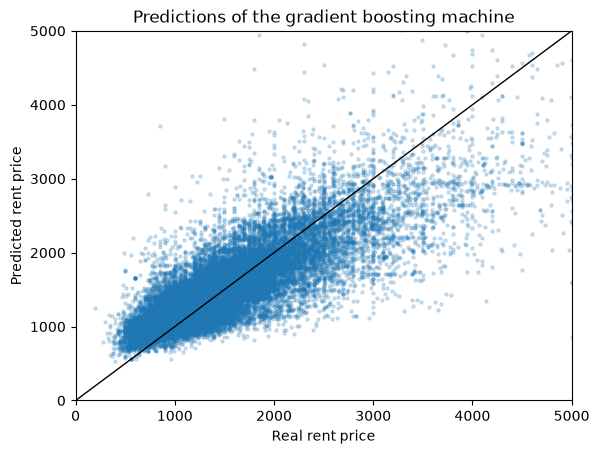

In [8]:
# Let's plot the predictions vs the true rent
# We zoom into the most common prices, because a few apartments cost more than 30000
predictions = gbm.predict(X_test)

plt.scatter(y_test, predictions, alpha=0.2, s=5)
plt.plot([0, 5000], [0, 5000], color="black", linewidth=1)
plt.xlim(0, 5000)
plt.ylim(0, 5000)
plt.xlabel("Real rent price")
plt.ylabel("Predicted rent price")
plt.title("Predictions of the gradient boosting machine")
plt.show()

With the default parameters, the gradient boosting machine is already a much better model than AdaBoost with its default parameters, and the predictions follow the diagonal.

Let's now change one hyperparameter at a time to understand what is going on.

### The number of trees

The gradient boosting machine adds the trees one after the other, so we can evaluate the ensemble after each new tree with `staged_predict`, and we obtain the whole curve by training the model only once.

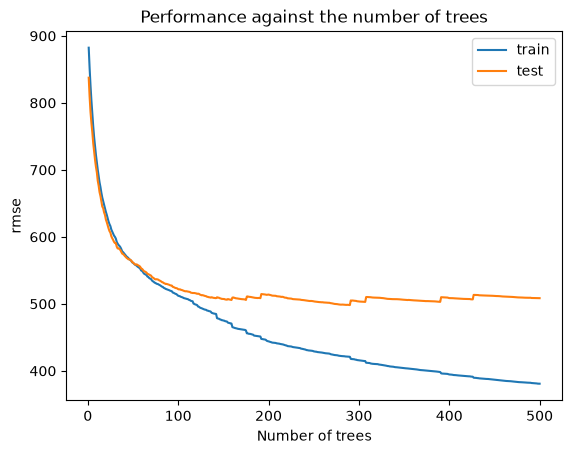

In [9]:
gbm = GradientBoostingRegressor(n_estimators=500, random_state=0)
gbm.fit(X_train, y_train)

train_curve = [root_mean_squared_error(y_train, p) for p in gbm.staged_predict(X_train)]
test_curve = [root_mean_squared_error(y_test, p) for p in gbm.staged_predict(X_test)]

trees = range(1, len(train_curve) + 1)

plt.plot(trees, train_curve, label="train")
plt.plot(trees, test_curve, label="test")
plt.xlabel("Number of trees")
plt.ylabel("rmse")
plt.title("Performance against the number of trees")
plt.legend()
plt.show()

At the beginning, each new tree reduces the error in both sets. After a few hundred trees, the error in the train set keeps going down, because every new tree fits the residuals of the train set a bit better, but the error in the test set stops improving. From that point on, the new trees learn the noise of the train set, and this is overfitting.

As opposed to random forests, in gradient boosting the number of trees is a regularization parameter, and too many trees may hurt the model.

### The learning rate

The learning rate multiplies the contribution of each tree, so with a small learning rate every tree corrects only a small part of the error, and we need more trees to reach the same performance.

Remember from the previous video: the learning rate controls the stride along the loss function towards its minimum.

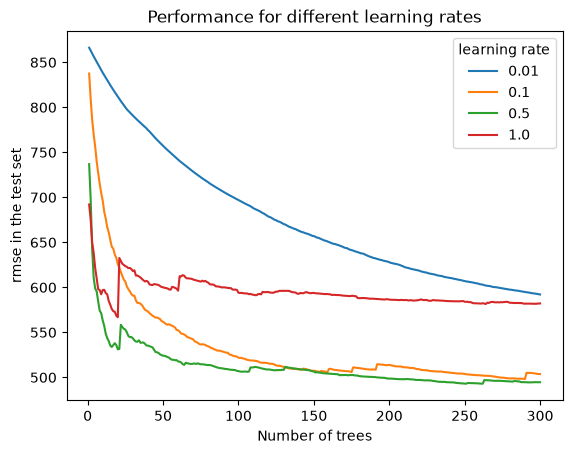

In [10]:
learning_rates = [0.01, 0.1, 0.5, 1.0]

curves = {}
for learning_rate in learning_rates:
    model = GradientBoostingRegressor(n_estimators=300, learning_rate=learning_rate, random_state=0)
    model.fit(X_train, y_train)
    curves[learning_rate] = [root_mean_squared_error(y_test, p) for p in model.staged_predict(X_test)]

curves = pd.DataFrame(curves)
curves.index = curves.index + 1

curves.plot()
plt.xlabel("Number of trees")
plt.ylabel("rmse in the test set")
plt.title("Performance for different learning rates")
plt.legend(title="learning rate")
plt.show()

With a learning rate of 0.01, the model is still learning after 300 trees, so it needs many more trees. With a learning rate of 1, the error drops very fast at the beginning and then it stops improving, and it does not seem to reach the minimum. It probably bounces back and forth and misses it.

The values in between give the best results. In practice, we use a small learning rate and a large number of trees, because smaller steps tend to generalize better, and the price we pay is training time.

### The loss function

The loss decides what the trees try to correct. With the squared error, each tree fits the residuals, so the very expensive apartments, with very large residuals, have a big influence on the model. The absolute error only looks at the sign of the residuals, and it estimates the median instead of the mean, so it is robust to outliers. The huber loss is a compromise: it behaves like the squared error for small residuals and like the absolute error for large ones. The point where it changes from one to the other is controlled by the parameter `alpha`.

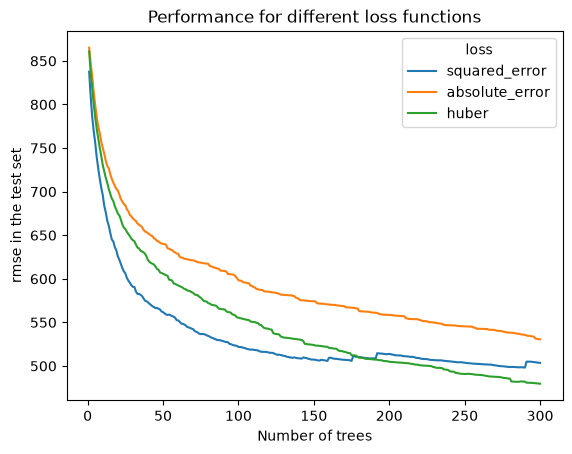

In [11]:
losses = ["squared_error", "absolute_error", "huber"]

curves = {}
results = {}
for loss in losses:
    model = GradientBoostingRegressor(n_estimators=300, loss=loss, random_state=0)
    model.fit(X_train, y_train)
    curves[loss] = [root_mean_squared_error(y_test, p) for p in model.staged_predict(X_test)]
    results[loss] = {
        "rmse": root_mean_squared_error(y_test, model.predict(X_test)),
        "mae": mean_absolute_error(y_test, model.predict(X_test)),
    }

curves = pd.DataFrame(curves)
curves.index = curves.index + 1

curves.plot()
plt.xlabel("Number of trees")
plt.ylabel("rmse in the test set")
plt.title("Performance for different loss functions")
plt.legend(title="loss")
plt.show()

In [12]:
# the performance after 300 trees
pd.DataFrame(results).T.round(1)

,rmse,mae
squared_error,503.6,261.4
absolute_error,530.6,254.9
huber,479.7,250.2


The robust losses learn more slowly, because they pay less attention to the large residuals, but after enough trees the huber loss returns a better model than the squared error, both in rmse and in mae.

The loss we optimise should match the metric we care about, so if large errors are what we want to avoid, the squared error makes sense, and if we want to be right for the typical apartment, the absolute error or the huber loss are better choices.

### Random features at each split: max_features

By default, each tree looks at all the features to find the best split. With `max_features`, each split only considers a random subset of the features, just like in the random forest. The trees become more different from each other, which reduces the variance of the ensemble, and training gets faster, because each split evaluates fewer features.

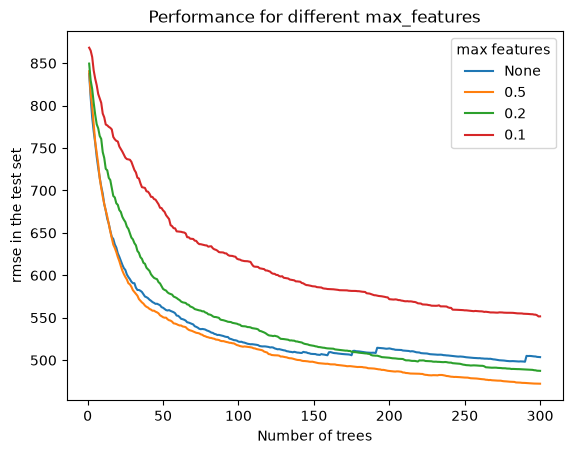

In [13]:
max_features = [None, 0.5, 0.2, 0.1]

curves = {}
for features in max_features:
    model = GradientBoostingRegressor(n_estimators=300, max_features=features, random_state=0)
    model.fit(X_train, y_train)
    curves[str(features)] = [root_mean_squared_error(y_test, p) for p in model.staged_predict(X_test)]

curves = pd.DataFrame(curves)
curves.index = curves.index + 1

curves.plot()
plt.xlabel("Number of trees")
plt.ylabel("rmse in the test set")
plt.title("Performance for different max_features")
plt.legend(title="max features")
plt.show()

Using half of the features at each split gives a better model than using all of them, and it trains in half the time. If we use too few features, the trees are too weak, because the most important features can be left out, and the model needs many more trees to compensate.

### Random rows for each tree: stochastic gradient boosting

With `subsample`, each tree is trained on a random sample of the rows, drawn **without replacement**. This is what Friedman called **stochastic gradient boosting**. Like with `max_features`, the randomness makes the trees different from each other, it reduces the variance of the ensemble, and it speeds up the training.

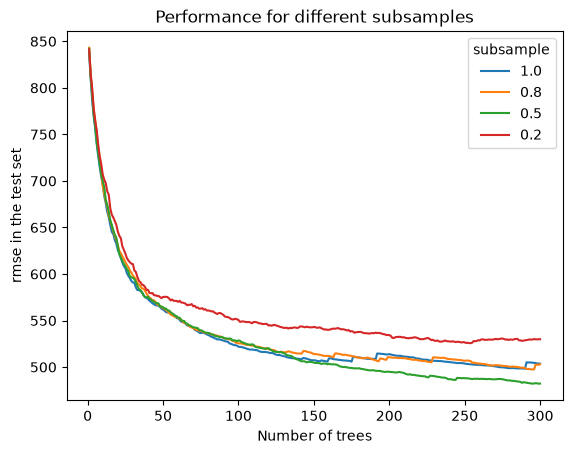

In [14]:
subsamples = [1.0, 0.8, 0.5, 0.2]

curves = {}
for subsample in subsamples:
    model = GradientBoostingRegressor(n_estimators=300, subsample=subsample, random_state=0)
    model.fit(X_train, y_train)
    curves[subsample] = [root_mean_squared_error(y_test, p) for p in model.staged_predict(X_test)]

curves = pd.DataFrame(curves)
curves.index = curves.index + 1

curves.plot()
plt.xlabel("Number of trees")
plt.ylabel("rmse in the test set")
plt.title("Performance for different subsamples")
plt.legend(title="subsample")
plt.show()

Training each tree on half of the apartments returns a slightly better model than using all of them. With only 20% of the rows, each tree sees too little data, and the model gets worse.

## Optimising the gradient boosting machine

We've seen that each of the hyperparameters has an effect on the performance of the model, and that some of them, like the number of trees and the learning rate, depend on each other. So let's go ahead and set up an automatic search for hyperparameters using randomised search.

In [15]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV

In [16]:
param_distributions = {
    "n_estimators": randint(100, 500),
    "learning_rate": loguniform(0.01, 0.5),
    "loss": ["squared_error", "absolute_error", "huber"],
    "max_depth": randint(2, 8),
    "min_samples_leaf": randint(1, 50),
    "max_features": uniform(0.2, 0.6),
    "subsample": uniform(0.4, 0.6),
}

search = RandomizedSearchCV(
    GradientBoostingRegressor(random_state=0),
    param_distributions,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=0,
    n_jobs=-1,
)

search.fit(X_train, y_train)

search.best_params_

{'learning_rate': np.float64(0.31402765970123275),
 'loss': 'squared_error',
 'max_depth': 7,
 'max_features': np.float64(0.7290412171129117),
 'min_samples_leaf': 26,
 'n_estimators': 477,
 'subsample': np.float64(0.7007946291560214)}

In [17]:
# the standard deviation tells us how much the metric changes across the folds
results = pd.DataFrame(search.cv_results_)
results = results.sort_values("rank_test_score")

results[["mean_test_score", "std_test_score", "rank_test_score"]].head(10).round(2)

,mean_test_score,std_test_score,rank_test_score
21,-484.95,58.59,1
16,-485.03,94.74,2
20,-494.52,101.12,3
3,-508.63,58.14,4
9,-516.54,62.95,5
19,-519.86,92.78,6
18,-532.67,102.15,7
25,-534.49,65.90,8
5,-535.33,102.71,9
8,-538.26,94.93,10


In [18]:
evaluate(search.best_estimator_, X_train, y_train, X_test, y_test)

train rmse: 280.56, r2: 0.9066
test rmse: 420.64, r2: 0.7660


The tuned model reduces the error in the test set from about 520 to about 420 dollars, so it is a big improvement over the default parameters. Notice that the search chose deeper trees, a learning rate that is larger than the default, and random samples of both the features and the rows.

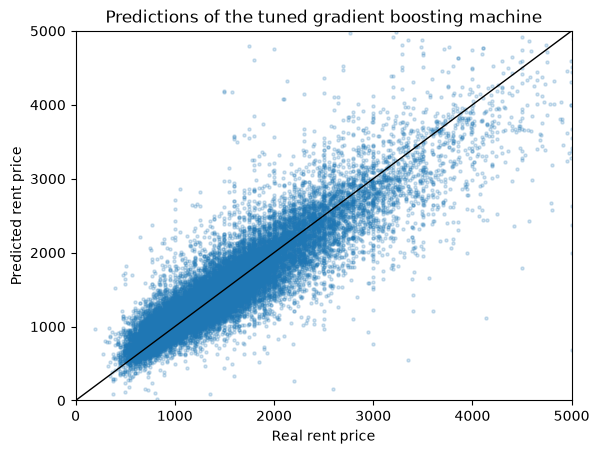

In [19]:
# Let's plot the predictions vs the true rent
# We zoom into the most common prices, because a few apartments cost more than 30000
predictions = search.predict(X_test)

plt.scatter(y_test, predictions, alpha=0.2, s=5)
plt.plot([0, 5000], [0, 5000], color="black", linewidth=1)
plt.xlim(0, 5000)
plt.ylim(0, 5000)
plt.xlabel("Real rent price")
plt.ylabel("Predicted rent price")
plt.title("Predictions of the tuned gradient boosting machine")
plt.show()

## Warm start: adding trees to a trained model

We don't know in advance how many trees we need. If we train a model with 100 trees and the error is still going down, we would have to train a new model with more trees from scratch, and train the first 100 trees all over again.

With `warm_start=True`, when we increase `n_estimators` and call `fit` again, the model keeps the trees it already has and only trains the new ones. So we can grow the model in steps, evaluate it after each step, and continue from where we left off if it is still improving.

To decide when to stop, we need data that the model did not see during training. We can't use the test set for this, because then the test set would be part of the training process, so we take a validation set out of the train set.

In [20]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=0)

X_tr.shape, X_val.shape

((55897, 39), (13975, 39))

In [21]:
%%time
# we start with 100 trees
gbm = GradientBoostingRegressor(n_estimators=100, warm_start=True, random_state=0)
gbm.fit(X_tr, y_tr)

val_curve = [root_mean_squared_error(y_val, p) for p in gbm.staged_predict(X_val)]

print(f"trees in the model: {len(gbm.estimators_)}")
print(f"best number of trees: {np.argmin(val_curve) + 1}")

trees in the model: 100
best number of trees: 100
CPU times: user 4.95 s, sys: 9.12 ms, total: 4.96 s
Wall time: 4.96 s


The best model is the one with all the trees, so the model is still improving, and it's worth adding more trees. We increase the number of trees to 200 and we fit again. Notice that the training takes about as long as the first time, because the model only trains the 100 new trees.

In [22]:
%%time
gbm.set_params(n_estimators=200)
gbm.fit(X_tr, y_tr)

val_curve = [root_mean_squared_error(y_val, p) for p in gbm.staged_predict(X_val)]

print(f"trees in the model: {len(gbm.estimators_)}")
print(f"best number of trees: {np.argmin(val_curve) + 1}")

trees in the model: 200
best number of trees: 200
CPU times: user 5.19 s, sys: 9.12 ms, total: 5.2 s
Wall time: 5.2 s


Instead of doing this by hand, we can add trees in a loop until the new trees stop paying off. Here, we stop when the last 100 trees reduce the error in the validation set by less than 5 dollars.

In [23]:
gbm = GradientBoostingRegressor(n_estimators=100, warm_start=True, random_state=0)

history = {}
previous_rmse = np.inf

while True:
    gbm.fit(X_tr, y_tr)
    rmse = root_mean_squared_error(y_val, gbm.predict(X_val))
    history[gbm.n_estimators] = rmse
    print(f"trees: {gbm.n_estimators}, validation rmse: {rmse:.2f}")

    if previous_rmse - rmse < 5:
        break

    previous_rmse = rmse
    gbm.set_params(n_estimators=gbm.n_estimators + 100)

trees: 100, validation rmse: 646.75
trees: 200, validation rmse: 626.69
trees: 300, validation rmse: 613.80
trees: 400, validation rmse: 608.06
trees: 500, validation rmse: 605.08


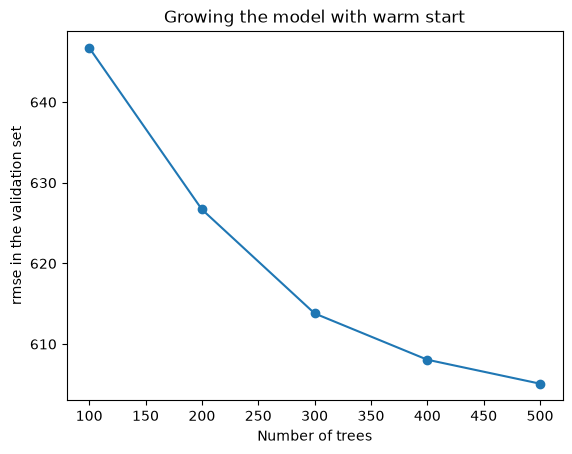

In [24]:
pd.Series(history).plot(marker="o")
plt.xlabel("Number of trees")
plt.ylabel("rmse in the validation set")
plt.title("Growing the model with warm start")
plt.show()

In [25]:
evaluate(gbm, X_tr, y_tr, X_test, y_test)

train rmse: 367.81, r2: 0.8361
test rmse: 469.75, r2: 0.7082


Scikit-learn can also do this automatically inside `fit`, with the parameter `n_iter_no_change`. The model separates a fraction of the train set as validation (`validation_fraction`), and it stops adding trees when the error in the validation set has not improved for `n_iter_no_change` trees in a row. Warm start gives us more control, because we decide how to evaluate the model and when to stop.

In [27]:
gbm = GradientBoostingRegressor(
    n_estimators=2000,
    n_iter_no_change=10,
    validation_fraction=0.2,
    random_state=0,
)

gbm.fit(X_train, y_train)

print(f"trees in the model: {gbm.n_estimators_}")
evaluate(gbm, X_train, y_train, X_test, y_test)

trees in the model: 388
train rmse: 439.78, r2: 0.7704
test rmse: 478.83, r2: 0.6968
